In [20]:
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path
import pandas as pd
import json

MANIFEST = Path('../data/manifest.json')

samples = pd.DataFrame(json.loads(MANIFEST.read_text()))
samples['commit_date'] = pd.to_datetime(samples['commit_date'], utc=True, format='ISO8601')
samples['jobs_per_workflow'] = samples['jobs'] / samples['workflows']

print(f'{len(samples)} repositories, {samples.workflows.sum()} workflows, {samples.jobs.sum()} jobs')
samples[['name', 'stars', 'primary_language', 'workflows', 'jobs', 'files', 'lines', 'commit_date']].sort_values('jobs', ascending=False)

30 repositories, 437 workflows, 925 jobs


,name,stars,primary_language,workflows,jobs,files,lines,commit_date
24,next.js,143371,JavaScript,29,95,35403,3208818,2026-11-06 23:17:30+00:00
0,rea,438278,TypeScript,35,79,7509,2394225,2026-11-06 23:13:15+00:00
7,vscode,195040,TypeScript,15,76,20972,7073702,2026-11-07 02:05:02+00:00
2,react,252274,JavaScript,26,74,7300,1178156,2026-11-06 19:43:46+00:00
20,spec-kit,148217,Python,20,70,1022,345923,2026-11-06 20:52:56+00:00
6,firecrawl,199284,TypeScript,33,65,2218,543946,2026-11-06 23:08:49+00:00
10,AutoGPT,187929,Python,38,64,10818,2074693,2026-11-05 21:18:08+00:00
19,langchain,149140,Python,27,47,3285,587715,2026-11-06 17:38:34+00:00
17,clash-verge-rev,156791,Rust,21,44,751,158127,2026-11-06 17:42:25+00:00
21,ComfyUI,145455,Python,29,36,1339,1929985,2026-11-07 00:06:23+00:00


In [21]:
columns = ['stars', 'forks', 'workflows', 'jobs', 'jobs_per_workflow', 'files', 'lines']

summary = samples[columns].describe().T[['min', '25%', '50%', '75%', 'max', 'mean']]
summary['total'] = samples[columns].sum()
summary.round(1)

,min,25%,50%,75%,max,mean,total
stars,127529.0,144399.8,170127.5,194833.2,438278.0,182466.4,5473993.0
forks,8534.0,14270.2,22668.5,41551.0,108587.0,32022.5,960676.0
workflows,1.0,3.5,12.5,24.8,38.0,14.6,437.0
jobs,1.0,6.0,21.0,46.2,95.0,30.8,925.0
jobs_per_workflow,1.0,1.3,1.9,2.5,17.0,2.5,74.5
files,197.0,618.2,1333.5,7077.8,37712.0,6058.8,181764.0
lines,9317.0,124026.2,379777.5,1623688.2,11347436.0,1378460.3,41353808.0


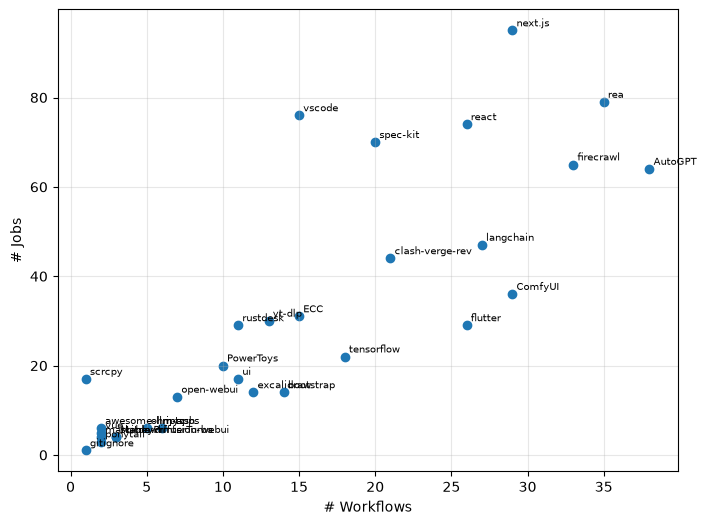

In [22]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(samples['workflows'], samples['jobs'])

for _, row in samples.iterrows():
    ax.annotate(row['name'], (row['workflows'], row['jobs']), fontsize=7, xytext=(3, 3), textcoords='offset points')

ax.set_xlabel('# Workflows')
ax.set_ylabel('# Jobs')
ax.grid(alpha=0.3)

plt.savefig('sample-workflows-jobs.pdf', bbox_inches='tight')
plt.show()

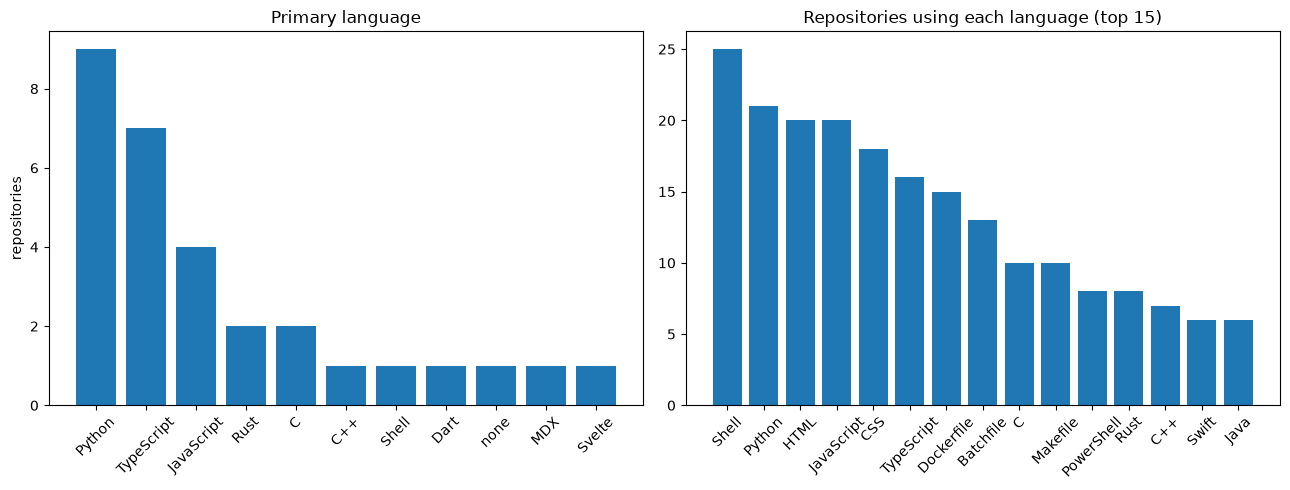

In [23]:
primary = samples['primary_language'].fillna('none').value_counts()
present = Counter(language for languages in samples['languages'] for language in languages)
present = pd.Series(present).sort_values(ascending=False).head(15)

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5))

left.bar(primary.index, primary.values)
left.set_title('Primary language')
left.set_ylabel('repositories')
left.tick_params(axis='x', rotation=45)

right.bar(present.index, present.values)
right.set_title('Repositories using each language (top 15)')
right.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

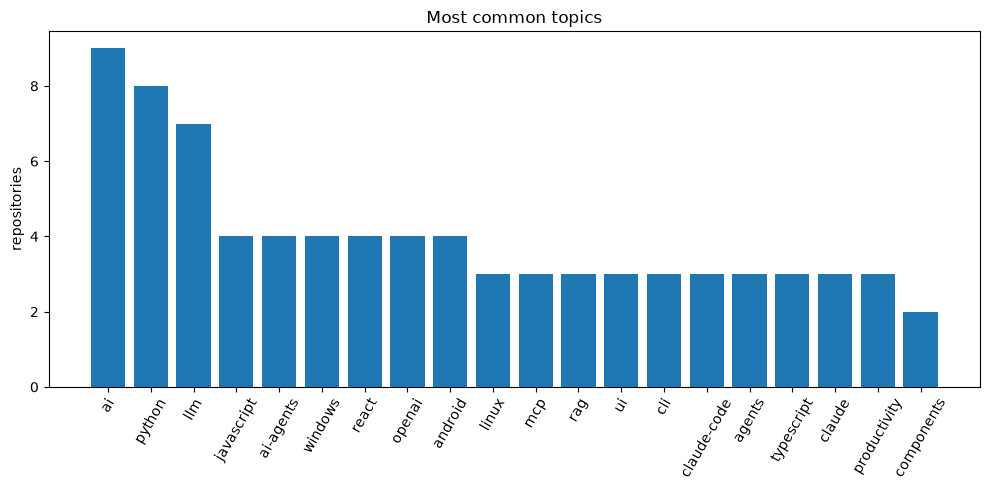

14 of 30 repositories have an AI topic: rea, ECC, firecrawl, markitdown, AutoGPT, ponytail, stable-diffusion-webui, open-webui, langchain, spec-kit, ComfyUI, awesome-llm-apps, MoneyPrinterTurbo, ui


In [24]:
AI_TOPICS = {'ai', 'llm', 'llms', 'ai-agents', 'agents', 'agentic-ai', 'claude', 'claude-code', 'anthropic', 'openai', 'chatgpt', 'generative-ai', 'rag', 'agent-skills'}

topics = pd.Series(Counter(topic for found in samples['topics'] for topic in found)).sort_values(ascending=False).head(20)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(topics.index, topics.values)
ax.set_title('Most common topics')
ax.set_ylabel('repositories')
ax.tick_params(axis='x', rotation=60)
plt.tight_layout()
plt.show()

ai = samples[samples['topics'].apply(lambda found: bool(AI_TOPICS & set(found)))]
print(f'{len(ai)} of {len(samples)} repositories have an AI topic: {", ".join(ai["name"])}')

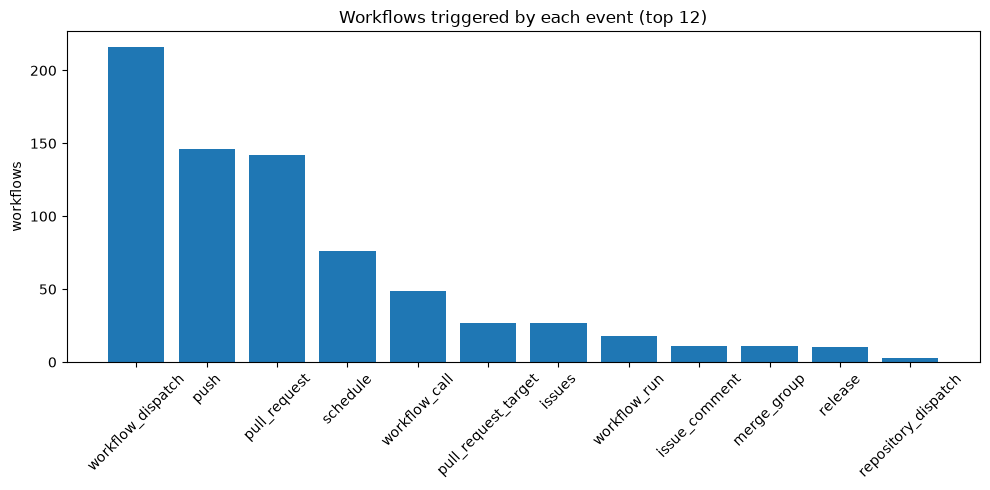

437 workflows, 17 distinct events, 1.7 events per workflow (max 5).
53% of workflows start on more than one event; 50% of triggers filter their payload (branches, tags, types, inputs).


In [25]:
per_workflow = triggers.groupby(['repo', 'workflow']).size()
events = triggers['event'].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(events.index[:12], events.values[:12])
ax.set_title('Workflows triggered by each event (top 12)')
ax.set_ylabel('workflows')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

print(f'{len(per_workflow)} workflows, {len(events)} distinct events, {per_workflow.mean():.1f} events per workflow (max {per_workflow.max()}).')
print(f'{(per_workflow > 1).mean():.0%} of workflows start on more than one event; {triggers["filtered"].mean():.0%} of triggers filter their payload (branches, tags, types, inputs).')